In [2]:
import pandas as pd
from datetime import datetime
from sklearn.model_selection import StratifiedKFold, KFold
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_graphviz
import graphviz
import seaborn as sns
import itertools
UTIL = [1, 1, 1, 1, 1, 0, 0]
import warnings
warnings.filterwarnings('ignore')


import os
os.environ.setdefault('DJANGO_SETTINGS_MODULE', 'conf.settings')

import django
django.setup()

from core.models import *
from core.dataframe import ViagensVazias, get_order_trecho





def seleciona_vazias(self, df, valor_limite=0):
    # PARA VAZIAS
    df['critica'] = 1
    if 0 < valor_limite < 1:
        print('Valor Limite: ')
    
        print(df.saldo_viagem.quantile(valor_limite))
        df.loc[(df.saldo_viagem < df.saldo_viagem.quantile(valor_limite)), 'critica'] = 0
    else:
        print('Valor Limite: ')
    
        print(valor_limite)
        df.loc[(df.saldo_viagem < 0), 'critica'] = 0
        
        
    df[df.critica == 0]
    return df


def seleciona_cheias(self, df, valor_limite=60):
    # PARA CHEIAS
    df['critica'] = 1
    df['proximo_trecho'] = df['trecho'].shift(-1)
    df.loc[(df.partida != df.partida.shift(-1)) & ((df.sentido.shift(-1)=='ida') | ((df.sentido == 'volta') & (df.sentido.shift(-1) == 0))), 'proximo_trecho'] = 0
    df['proximo_trecho2'] = df['trecho'].shift(-2)
    df.loc[(df.partida != df.partida.shift(-2)) & ((df.sentido.shift(-2)=='ida') | ((df.sentido == 'volta') & (df.sentido.shift(-2) == 0))), 'proximo_trecho2'] = 0
    df['acumulado'] = df.trecho + df.proximo_trecho + df.proximo_trecho2
    df.loc[(df.acumulado > valor_limite), 'critica'] = 0
    df[df.critica == 0]
    return df


def calcular_sobreposicao(self=None):
    df = self.get_df()
    df.columns = ['ponto', 'trecho', 'partida', 'sentido', 'linha', 'sc', 'eixo', 'km_ida', 'km_volta', 'custo_por_km', 'receita']
    df = df[~pd.isnull(df.ponto)]
    results = []
    for linha1, df1 in df.groupby('linha'):
        pontos_linha1 = df1.trecho.unique()
        for linha2, df2 in df.groupby('linha'):
            pontos_linha2 = df2.trecho.unique()
            total = len(np.unique(np.union1d(pontos_linha1, pontos_linha2)))
            #print('\n\n\n', linha1, linha2)
            #print(np.unique(np.union1d(pontos_linha1, pontos_linha2)))
            #print(np.intersect1d(pontos_linha1, pontos_linha2, assume_unique=True))
            inter = len(np.intersect1d(pontos_linha1, pontos_linha2, assume_unique=True))
            #print(inter, total, inter/total)
            results.append((linha1, linha2, inter/total))
    df = pd.DataFrame(results, columns=['L1', 'L2', 'sobreposicao'])
    return df
            
                
            
    
    
def calcular(self=None, tipo='vazias', tipo_dia_hora='uteis', valor_limite=0):
    df = self.get_df()
    df.columns = ['ponto', 'trecho', 'partida', 'sentido', 'linha', 'sc', 'eixo', 'km_ida', 'km_volta', 'custo_por_km', 'receita']
    eixos = {e: i for i, e in enumerate(sorted(list(df.eixo.unique())))}
    df['dia_semana'] = pd.to_datetime(df['partida']).dt.dayofweek
    df['util'] = pd.to_datetime(df['partida']).dt.dayofweek.apply(lambda x: UTIL[x])
    df['hora'] = df.partida.dt.hour
    df['dia'] = df.partida.dt.day
    
    
    if tipo_dia_hora == 'uteis':
        #df = df[(df.hora > 7) & (df.hora < 14)]
        #df = df[df.hora > 19]
        # Uteis
        df = df[df.util > 0]
    elif tipo_dia_hora == 'sabado':
        # Sábado
        df = df[df.dia_semana == 5]
    elif tipo_dia_hora == 'domingo':
        # DOmingo
        df = df[df.dia_semana == 6]
    


    ordem_ponto = {(p, s): o for p, o, s in OrdemPontosLinha.objects.select_related().all().values_list('ponto__trecho__nome', 'ordem', 'sentido').distinct()}
    df['ordem_ponto'] = np.vectorize(lambda p, s: ordem_ponto.get((p, s), -1))(df.trecho.values, df.sentido.values)
    
    #
    
    df = df.groupby(['linha', 'sc', 'eixo', 'dia', 'partida', 'hora', 'sentido', 'ordem_ponto', 'km_ida', 'km_volta', 'custo_por_km']).agg({'trecho': 'count', 'receita': 'sum'}).reset_index()
    df['total_pass_viagem'] = df.groupby(['linha', 'sc', 'eixo', 'dia', 'hora', 'partida', 'sentido'])['trecho'].transform('sum')
    df['total_receita_viagem'] = df.groupby(['linha', 'sc', 'eixo', 'dia', 'hora', 'partida', 'sentido'])['receita'].transform('sum')
    df.loc[df.sentido == 'ida', 'custo_viagem'] = df.loc[df.sentido == 'ida', 'km_ida'] * df.loc[df.sentido == 'ida', 'custo_por_km']
    df.loc[df.sentido == 'volta', 'custo_viagem'] = df.loc[df.sentido == 'volta', 'km_volta'] * df.loc[df.sentido == 'volta', 'custo_por_km']
    if tipo == 'cheias':
        #PARA CHEIAS
        df = seleciona_cheias(self, df, valor_limite)
    ## fim
    df = df.groupby(['linha', 'sc', 'eixo', 'dia', 'hora', 'partida', 'sentido']).first().reset_index()
    df['saldo_viagem'] = df['total_receita_viagem'] - df['custo_viagem']
    #print(df)
    
    a_trocar = {
        'ida' : 0,
        'volta' : 1
    }
    #print('Eixos', eixos)
    df.sentido = df.sentido.map(a_trocar)
    df.eixo = df.eixo.map(eixos)
    df.sc = df.sc.map({True: 1, False: 0, None: -1})
    df.linha = df.linha.astype(int)
    if tipo == 'vazias':
        df = seleciona_vazias(self, df, valor_limite)
    return df
    

def get_xy(self, df):
    x = df[['hora', 'sentido' , 'linha', 'eixo', 'sc']]#'ordem_ponto', Ramdom Forest (feature importance random forestr)
    y = df['critica']
    return x, y
 




In [3]:
def dummy(self, x, y):
    treino_x, teste_x, treino_y, teste_y = train_test_split(x, y,
                                                             test_size = 0.25,
                                                             stratify = y)
    print("Treinaremos com %d elementos e testaremos com %d elementos" % (len(treino_x), len(teste_x)))

    dummy_mostfrequent = DummyClassifier()
    dummy_mostfrequent.fit(treino_x, treino_y)
    acuracia = dummy_mostfrequent.score(teste_x, teste_y) * 100

    print("A acurácia do dummy foi %.2f%%" % acuracia)
                                                  
        
#dummy(vv, x, y)


                                                                
def imprime_resultados(results):
    media = results['test_score'].mean()
    desvio = results['test_score'].std()
    print("Accuracy médio %.2f" % media)
    print("Intervalo [%.2f, %.2f]" % (media - 2 * desvio, media + 2 * desvio))


def roda_modelo(ClasseModelo, Scaler=None, **kwargs):
    cv = StratifiedKFold(n_splits = 10)
    if Scaler is None:
        modelo = ClasseModelo(**kwargs)
        results = cross_validate(modelo, x, y, cv = cv, return_train_score=True)
    else:
        scaler = Scaler()
        modelo = ClasseModelo(**kwargs)
        pipeline = Pipeline([('transformacao',scaler), ('estimador',modelo)])
        results = cross_validate(pipeline, x, y, cv = cv,  return_train_score=True)
        
    fit_time = results['fit_time'].mean()
    score_time = results['score_time'].mean()
    train_score = results['train_score'].mean() * 100
    test_score = results['test_score'].mean() * 100
    train_std =  (results['train_score'] * 100).std()
    test_std =  (results['test_score'] * 100).std()
    tabela = list(kwargs.values()) + [train_score, train_std, test_score, test_std, fit_time, score_time]
    #imprime_resultados(results)

    return tabela

def busca(ClasseModelo, dict_params={}, Scaler=None):
    print(ClasseModelo)
    if dict_params:
        df = pd.DataFrame(list(itertools.product(*dict_params.values())), columns=dict_params.keys())
        resultados = []
        for i, combination in df.iterrows():
            if i%10 == 0:
                print(dict(combination))
            tabela = roda_modelo(ClasseModelo, Scaler, **dict(combination))
            resultados.append(tabela)
    else:
        resultados = [roda_modelo(ClasseModelo, Scaler)]
        
    resultados = pd.DataFrame(resultados, columns= list(dict_params.keys()) + ["train", 'train_std', "test", 'test_std', "fit_time", "score_time"])
    return resultados

In [4]:

def run():
    rss = []

    from sklearn.linear_model import LogisticRegression
    from sklearn.naive_bayes import GaussianNB
    C = 10






    resultados = busca(DummyClassifier, {})
    resultados = resultados.sort_values("test", ascending=False)
    resultados['modelo'] = 'DummyClassifier'
    rss.append(resultados)
    print(resultados.sort_values("test", ascending=False))


    '''


    params = {
        'penalty': [ 'l2'],
        'C': [C],
        'multi_class': ['multinomial', 'ovr']
        #'gamma': ['auto', 'scale']
    }

    resultados = busca(LogisticRegression, params)
    resultados = resultados.sort_values("test", ascending=False)
    resultados['modelo'] = 'LogisticRegression'
    rss.append(resultados)
    print(resultados.sort_values("test", ascending=False))

    params_NB = {'var_smoothing': np.logspace(0,-9, num=100)}
    print(list(np.logspace(0,-9, num=100)))
    resultados = busca(GaussianNB, params_NB)
    resultados = resultados.sort_values("test", ascending=False)
    resultados['modelo'] = 'GaussianNB'
    rss.append(resultados)
    print(resultados.sort_values("test", ascending=False))

    from sklearn.neural_network import MLPClassifier

    parameter_space = {
        'hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
        'activation': ['tanh', 'relu'],
        #'solver': ['sgd', 'adam'],
        #'alpha': [0.0001, 0.05],
        #'learning_rate': ['constant','adaptive'],
    }

    resultados = busca(MLPClassifier, parameter_space)
    resultados = resultados.sort_values("test", ascending=False)
    resultados['modelo'] = 'MLPClassifier'
    rss.append(resultados)
    print(resultados.sort_values("test", ascending=False))




    params = {
        #'kernel': ['poly']
        'kernel': ['linear', 'poly', 'rbf'],
        'degree': [2, 3, 4],
        #'gamma': ['auto', 'scale']
    }

    resultados = busca(SVC, params, StandardScaler)
    resultados = resultados.sort_values("test", ascending=False)
    resultados['modelo'] = 'SVC'
    rss.append(resultados)
    print(resultados.sort_values("test", ascending=False))





    resultados.head()

    params = {
        'max_depth': [3, 5, 7, 11, 15, 17, 20],
        'min_samples_leaf': [2, 32, 128, 256, 512, 1000],
        'min_samples_split': [2, 32, 128, 512],
    }
    from sklearn.ensemble import RandomForestClassifier
    resultados = busca(RandomForestClassifier, params)
    resultados = resultados.sort_values("test", ascending=False)
    resultados['modelo'] = 'RandomForestClassifier'
    rss.append(resultados)
    print(resultados.sort_values("test", ascending=False))
    '''
    params = {
        'max_depth': [3, 5, 7, 11, 15, 17, 20],
        'min_samples_leaf': [2, 32, 128, 256, 512, 1000],
        'min_samples_split': [2, 32, 128, 512],
    }
    resultados = busca(DecisionTreeClassifier, params)
    corr = resultados.corr()

    sns.set(style="white")

    # Generate a mask for the upper triangle
    mask = np.zeros_like(corr, dtype=np.bool)
    mask[np.triu_indices_from(mask)] = True

    # Set up the matplotlib figure
    f, ax = plt.subplots(figsize=(11, 9))

    # Generate a custom diverging colormap
    cmap = sns.diverging_palette(220, 10, as_cmap=True)

    # Draw the heatmap with the mask and correct aspect ratio
    sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
                square=True, linewidths=.5, cbar_kws={"shrink": .5})

    resultados['time'] = resultados['fit_time'] + resultados['score_time']
    resultados = resultados.sort_values(['test', 'max_depth',"time"], ascending=[False, True, True])
    resultados['modelo'] = 'DecisionTreeClassifier'
    rss.append(resultados)

    r_final = pd.concat(rss, ignore_index=True)
    r_final.to_excel('Geral ' + tipo + ' ' + tipo_dia + ' ' + str(valor_limite) +' std.xlsx')

    print(resultados.test)
    print(resultados.head())

    return resultados.head().reset_index().loc[0, list(params.keys())].astype(int)

In [5]:
#df = calcular_sobreposicao(self=vv)

In [6]:
#pd.pivot_table(df, columns='L2', index='L1', values= 'sobreposicao').to_excel('sobreposicao.xlsx')
#df.linha.unique()

In [7]:
linhas = ['051', '057', '058', '065', '068','069', '108', '711', '712', '715', '716']
viagens = ViagemDePassageiro.objects.filter(partida_embarque__linha__numero__in=linhas).filter(horario__year__gte=2020)
vv = ViagensVazias(viagens)

In [13]:
tipo_dia = 'uteis'
tipo = 'vazias'
valor_limite = 0


df = calcular(self=vv, tipo=tipo, tipo_dia_hora=tipo_dia, valor_limite=valor_limite)

Valor Limite: 
0


<class 'sklearn.dummy.DummyClassifier'>
       train  train_std       test  test_std  fit_time  score_time  \
0  65.063752   0.008096  65.063752   0.07286  0.005882    0.000798   

            modelo  
0  DummyClassifier  
<class 'sklearn.tree._classes.DecisionTreeClassifier'>
{'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
{'max_depth': 3, 'min_samples_leaf': 128, 'min_samples_split': 128}
{'max_depth': 3, 'min_samples_leaf': 1000, 'min_samples_split': 2}
{'max_depth': 5, 'min_samples_leaf': 32, 'min_samples_split': 128}
{'max_depth': 5, 'min_samples_leaf': 512, 'min_samples_split': 2}
{'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 128}
{'max_depth': 7, 'min_samples_leaf': 256, 'min_samples_split': 2}
{'max_depth': 7, 'min_samples_leaf': 1000, 'min_samples_split': 128}
{'max_depth': 11, 'min_samples_leaf': 128, 'min_samples_split': 2}
{'max_depth': 11, 'min_samples_leaf': 512, 'min_samples_split': 128}
{'max_depth': 15, 'min_samples_leaf': 32, 'min_sample

max_depth             11
min_samples_leaf     128
min_samples_split     32
Name: 0, dtype: int32

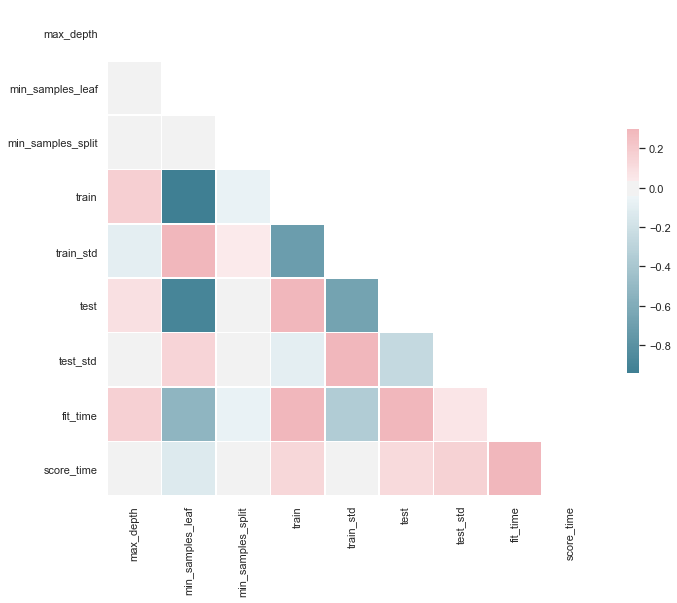

In [14]:
x, y = get_xy(vv, df)


best = run()
best

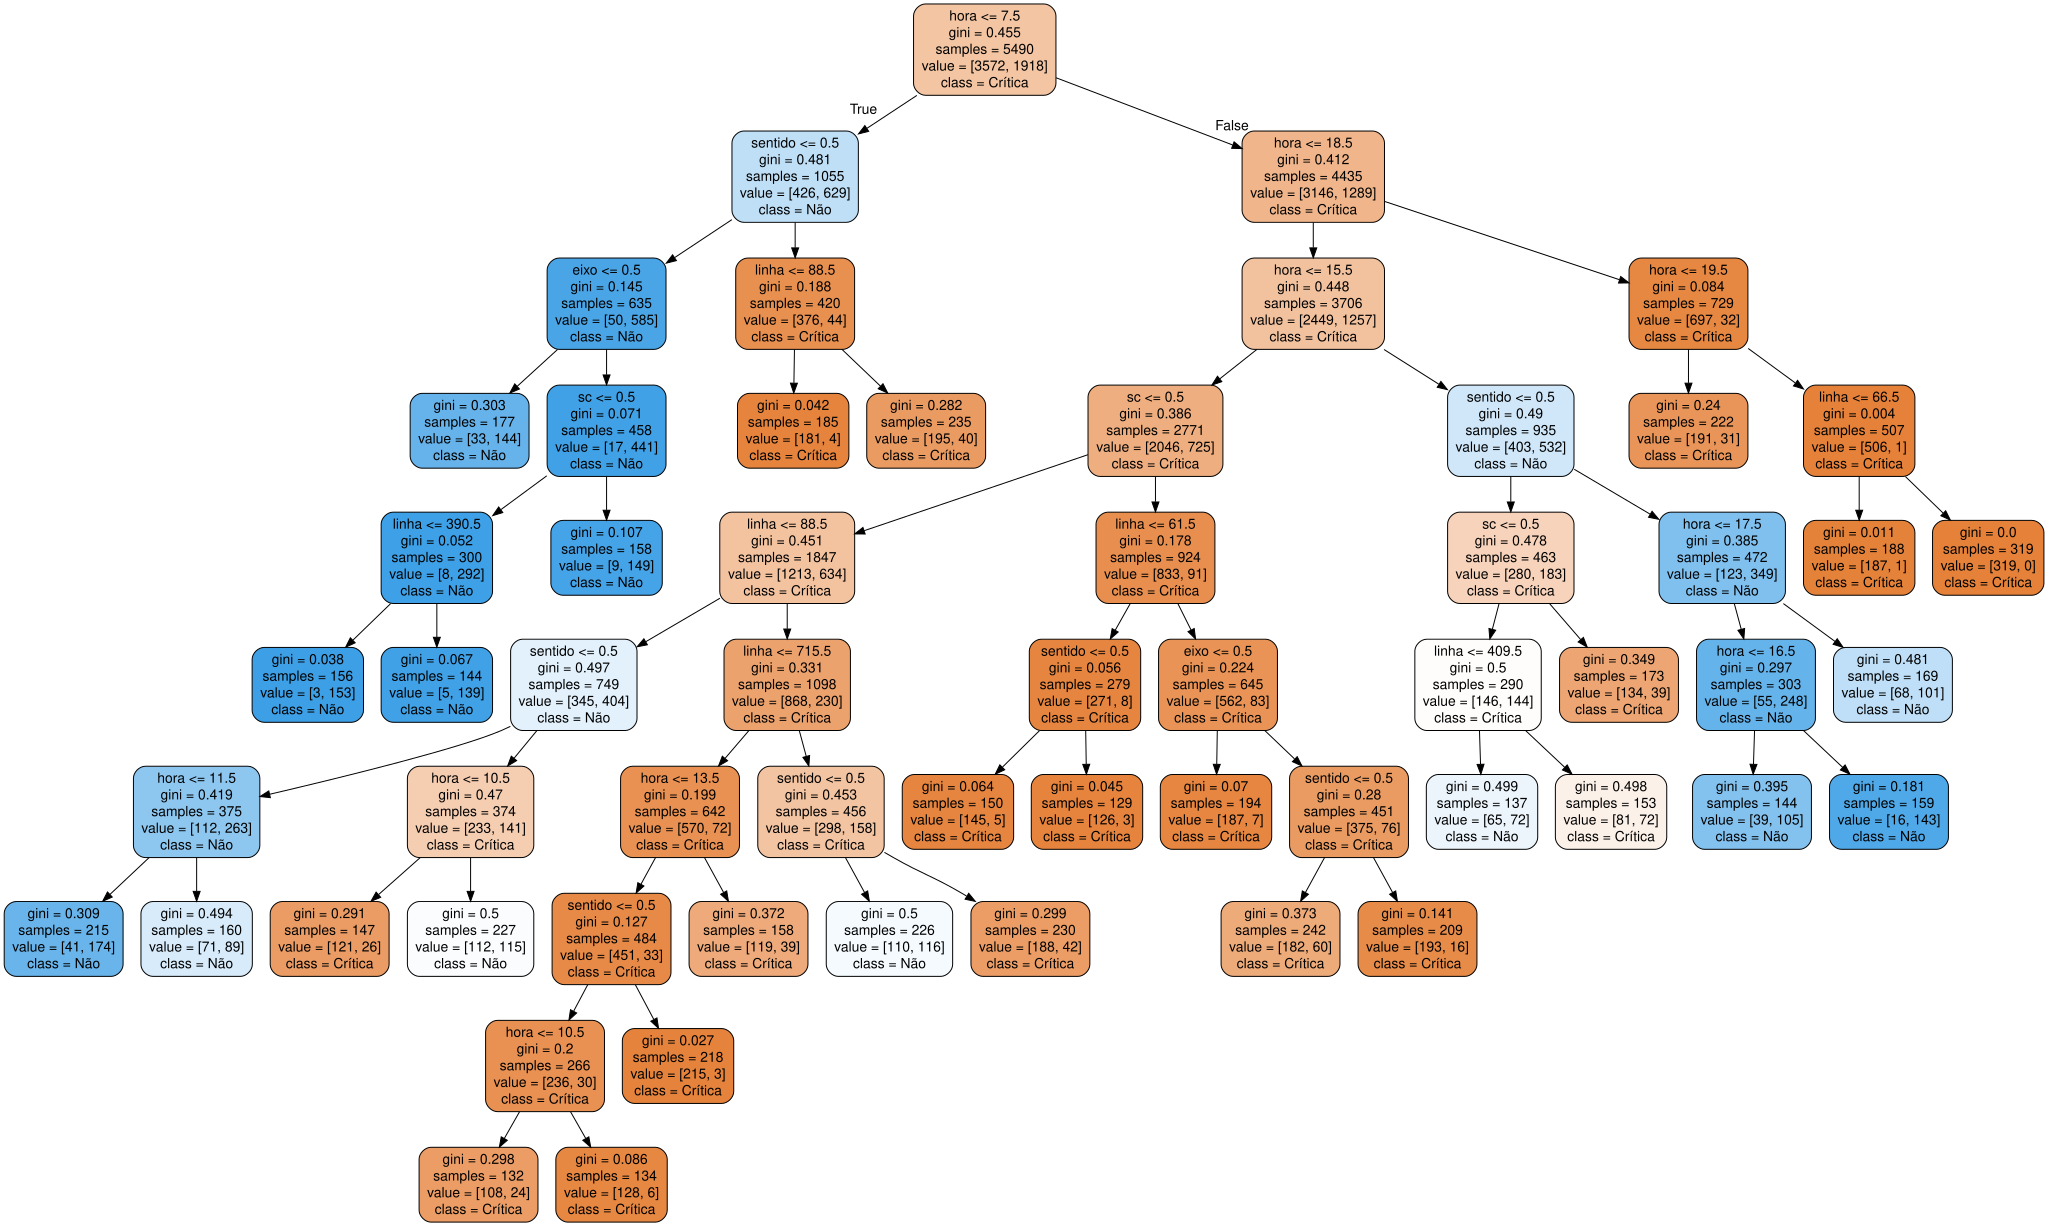

In [15]:

modelo = DecisionTreeClassifier(**dict(best))
modelo.fit(x, y)


features = x.columns
dot_data = export_graphviz(modelo, out_file=None,
                           filled = True,
                           rounded = True,
                           feature_names = features,
                           class_names = ["Crítica", "Não"])
grafico = graphviz.Source(dot_data)
grafico

In [16]:
dict(best)

{'max_depth': 11, 'min_samples_leaf': 128, 'min_samples_split': 32}

In [17]:
grafico.format = 'png'
grafico.render('dtree_render ' + tipo + ' ' + tipo_dia + ' ' + str(valor_limite),view=True)

'dtree_render vazias uteis 0.png'

In [31]:
1


1